In [42]:
# Personal parameters
SID4 = 2733
SEED = 2733
SLICE = 733
HP_ID = 3
CLS_A = 3
CLS_B = 7

# Reproducibility
import random
import numpy as np
import torch

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print({
    "SID4": SID4,
    "SEED": SEED,
    "SLICE": SLICE,
    "HP_ID": HP_ID,
    "CLS_A": CLS_A,
    "CLS_B": CLS_B
})

{'SID4': 2733, 'SEED': 2733, 'SLICE': 733, 'HP_ID': 3, 'CLS_A': 3, 'CLS_B': 7}


# Diffusion Concept

### Forward Diffusion, Noise Prediction, and Reverse Intuition

This  focuses on:

- how noise is gradually added to images
- how a noisy image can be sampled at any timestep
- why diffusion models predict noise
- what the model input and output look like

We use the MNIST dataset, which contains 60,000 handwritten digit images.
Each image is grayscale and has shape 1 × 28 × 28.



In [1]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

## 1. Device

We use GPU if available, otherwise CPU.

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


## 2. Load MNIST

We load the MNIST dataset, which contains small clothing images. These images will be our starting point for the diffusion process.

Each image has shape $1 \times 28 \times 28$.

We normalize images so pixel values range from -1 to 1 instead of 0 to 1. Neural networks train more stably when inputs are centered around zero.

In [3]:
#We normalize images so pixel values range from -1 to 1 instead of 0 to 1.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))   # map [0,1] -> [-1,1]
])

In [4]:
dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 341kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.21MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.3MB/s]


In [25]:
#The DataLoader feeds images to the model in batches of 32.
loader = DataLoader(dataset, batch_size=128, shuffle=True)

In [6]:
class_names = [str(i) for i in range(10)]

In [7]:
#Moves tensors to the same device as the model.
images, labels = next(iter(loader))
images = images.to(device)

#32 images, 1 channel(grayscale), 28x28 pixels
print("Batch shape:", images.shape)

Batch shape: torch.Size([32, 1, 28, 28])


## 3. Utility function for display

The dataset was normalized to `[-1, 1]`.

For plotting, it is easier to map values back to `[0, 1]`.

In [8]:
def denorm(x):
    return (x.clamp(-1, 1) + 1) / 2

## 4. Diffusion schedule

We define a simple linear noise schedule with:

- total diffusion steps: $T = 100$
- $\beta_t$ increasing linearly from $0.0001$ to $0.02$

Then we define:


$$\alpha_t = 1 - \beta_t$$

$$\bar{\alpha}_t = \prod_{i=1}^t \alpha_i$$

### Intuition
- $β_t$ controls how much noise is added at each step
- $α_t$ controls how much signal remains at each step
- $ᾱ_t$ tells us how much of the original image remains after many steps

his code defines the noise schedule for the diffusion process. It creates a sequence of noise values 𝛽𝑡 that gradually increase from 0.0001 to 0.02 over 100 steps, meaning we add a little more noise at each step. Using these values, the code computes
$$\alpha_t = 1 - \beta_t$$

to represent how much of the original image signal remains, and then calculates the cumulative product $\bar{\alpha}_t$, which tells us how much of the original image survives after multiple steps of noise. The square root terms are precomputed so they can be easily used later to generate noisy images during the diffusion process

In [9]:
#total number of diffusion steps
T = 100

In [10]:
#the noise schedule range
beta_start = 0.0001
beta_end = 0.02

#noise schedule where noise gradually increases across diffusion steps.
betas = torch.linspace(beta_start, beta_end, T, device=device)   # [T]

In [11]:
# beta  = how much noise we add
# alpha = how much of the original signal we keep.
alphas = 1.0 - betas                                             # [T]
alpha_bars = torch.cumprod(alphas, dim=0)                        # [T]

In [12]:
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

In [13]:
print("betas shape:", betas.shape)
print("alphas shape:", alphas.shape)
print("alpha_bars shape:", alpha_bars.shape)

betas shape: torch.Size([100])
alphas shape: torch.Size([100])
alpha_bars shape: torch.Size([100])


## 5. Visualize the noise schedule

These plots show:

- `β_t`: noise added per step
- `α_t`: signal retained per step
- `ᾱ_t`: cumulative signal remaining

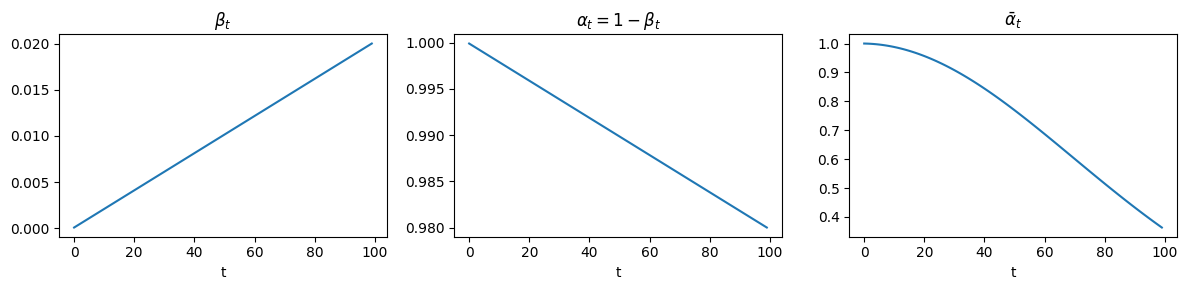

In [14]:
plt.figure(figsize=(12, 3))

plt.subplot(1, 3, 1)
plt.plot(betas.cpu().numpy())
plt.title(r"$\beta_t$")
plt.xlabel("t")

plt.subplot(1, 3, 2)
plt.plot(alphas.cpu().numpy())
plt.title(r"$\alpha_t = 1-\beta_t$")
plt.xlabel("t")

plt.subplot(1, 3, 3)
plt.plot(alpha_bars.cpu().numpy())
plt.title(r"$\bar{\alpha}_t$")
plt.xlabel("t")

plt.tight_layout()
plt.show()

## 6. Closed-form forward diffusion

Instead of adding noise step-by-step, we can directly sample a noisy version of the clean image at timestep $t$ using:

$$x_t = \sqrt{\bar{\alpha_t}}x_0 + \sqrt{1 - \bar{\alpha_t}} ϵ$$

where
$$\epsilon \sim \mathcal{N}(0, 1)$$


### Important idea
This means we can jump directly from clean image $x_0$ to noisy image $x_t$ for any timestep $t$.

The equation simply says noisy image = (some amount of original image) + (some amount of noise)

the coefficients control the balance.

This function generates a noisy version of a clean image at a specific diffusion timestep $t$. Instead of adding noise step-by-step, it uses the closed-form diffusion equation to directly compute $x_t$ from the original image $x_0$. It samples random Gaussian noise and mixes it with the image using precomputed coefficients $\sqrt{\bar{\alpha_t}}$ and $\sqrt{1 - \bar{\alpha_t}}$. The function returns the noisy image $x_t$ and the noise that was added, which the model will later learn to predict.

In [15]:
def q_sample(x0, t, noise=None):
    """
    Sample x_t directly from x_0 using the forward diffusion formula.

    Args:
        x0:    [B, 1, 28, 28] // clean image batch
        t:     [B] integer timesteps in [0, T-1]
        noise: optional Gaussian noise of same shape as x0

    Returns:
        xt:    noisy image at timestep t
        noise: sampled Gaussian noise
    """
    #generate random gaussian noise with the same shape as img.
    if noise is None:
        noise = torch.randn_like(x0)

    #.view(-1,1,1,1) reshapes it so it can braodcast across the image tensor.
    sqrt_ab = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    sqrt_1mab = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)

    xt = sqrt_ab * x0 + sqrt_1mab * noise
    return xt, noise

## 7. Visualize one image across timesteps

We take one FashionMNIST image and show how it becomes noisier over time.

Expected progression:

- early timestep → mostly clean
- mid timestep → partially corrupted
- late timestep → nearly pure noise

This code visualizes the forward diffusion process on one sample image from the dataset. It selects a single image and generates noisy versions at different timesteps using the q_sample() function. Each subplot shows how the image becomes progressively noisier as
𝑡 increases. This helps students see how diffusion gradually destroys the original image until it becomes mostly noise.

In [16]:
sample = images[0:1]
sample_label = labels[0].item()

In [17]:
timesteps = [0, 9, 29, 59, 99]

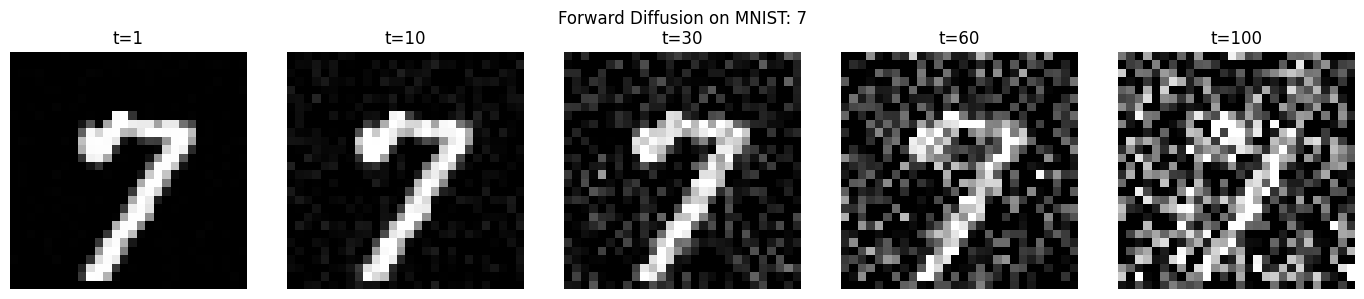

In [19]:
fig, axes = plt.subplots(1, len(timesteps), figsize=(14, 3))
for ax, t in zip(axes, timesteps):
    t_tensor = torch.tensor([t], device=device)
    xt, _ = q_sample(sample, t_tensor)
    ax.imshow(denorm(xt[0, 0]).detach().cpu(), cmap="gray")
    ax.set_title(f"t={t+1}")
    ax.axis("off")

plt.suptitle(f"Forward Diffusion on MNIST: {class_names[sample_label]}")
plt.tight_layout()
plt.show()

## 8. What is the model trying to predict?

A diffusion model is trained to predict the noise that was added.

To make that intuition clearer, we show:

- the clean image $x_0$
- the noisy image $x_t$
- the true sampled noise $\epsilon$

at a few different timesteps.


This code shows how diffusion corrupts an image with noise. For a few different timesteps, it displays three images: the original clean image, the noisy version of the image at that timestep, and the random noise that was added. As the timestep increases, the noisy image looks more and more like pure noise. This helps visualize how diffusion gradually destroys the image by mixing it with random noise.

In [20]:
compare_timesteps = [4, 49, 94]

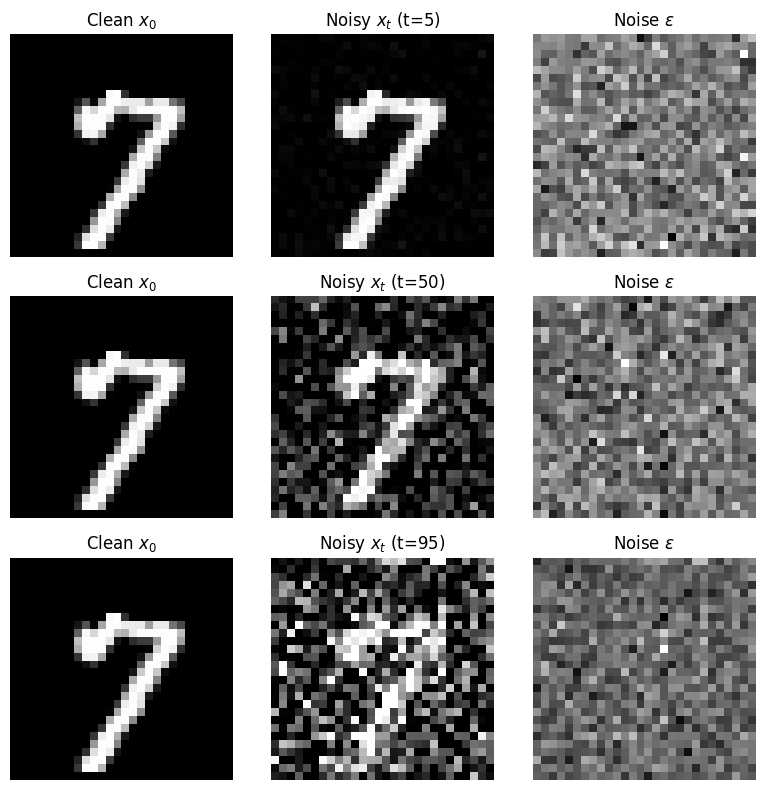

In [21]:
fig, axes = plt.subplots(len(compare_timesteps), 3, figsize=(8, 8))

for row, t in enumerate(compare_timesteps):
    t_tensor = torch.tensor([t], device=device)
    xt, eps = q_sample(sample, t_tensor)

    axes[row, 0].imshow(denorm(sample[0, 0]).detach().cpu(), cmap="gray")
    axes[row, 0].set_title("Clean $x_0$")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(denorm(xt[0, 0]).detach().cpu(), cmap="gray")
    axes[row, 1].set_title(f"Noisy $x_t$ (t={t+1})")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(eps[0, 0].detach().cpu(), cmap="gray")
    axes[row, 2].set_title("Noise $\\epsilon$")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.show()

## 9. Key DDPM idea: if we know the noise, we can recover the clean image

Starting from the forward diffusion equation:

$$x_t = \sqrt{\bar{\alpha_t}}x_0 + \sqrt{1 - \bar{\alpha_t}} ϵ$$

we can rearrange to recover the clean image:

$$x_0 = \frac{x_t - \sqrt{1 - \bar{\alpha_t}} ϵ}{\sqrt{\bar{\alpha_t}}}$$

### Core lesson
If the model can predict the noise well, then it can help us reconstruct the original image.

This code shows an important DDPM idea: if we know the exact noise that was added, we can recover the original clean image. The function `recover_x0_from_noise` uses the diffusion formula rearranged to estimate $x_0$ from the noisy image $x_t$ and the true noise $\epsilon$.

Then the code picks one timestep, creates a noisy image, reconstructs the clean image, and plots all three: original, noisy, and recovered. The main takeaway for students is that the model's job is to predict the noise well, because once the noise is known, the clean image can be reconstructed.

In [ ]:
def recover_x0_from_noise(xt, t, eps):
    """
    Recover x_0 from x_t if the true epsilon is known.
    """
    sqrt_ab = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    sqrt_1mab = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)

    x0_hat = (xt - sqrt_1mab * eps) / sqrt_ab
    return x0_hat

## 10. How do we train the model to learn the noise

During training, each image is paired with:

- a randomly sampled timestep $t$
- a noisy version $x_t$
- the true noise $\epsilon$

So the model learns the mapping:

$$(x_t, t) \rightarrow \epsilon$$

This is the core DDPM training setup.

In [26]:
batch_x0, batch_y = next(iter(loader))
batch_x0 = batch_x0.to(device)

t = torch.randint(0, T, (batch_x0.size(0),), device=device)
xt, eps = q_sample(batch_x0, t)

print("x0 shape:", batch_x0.shape)
print("xt shape:", xt.shape)
print("eps shape:", eps.shape)
print("t shape:", t.shape)

x0 shape: torch.Size([128, 1, 28, 28])
xt shape: torch.Size([128, 1, 28, 28])
eps shape: torch.Size([128, 1, 28, 28])
t shape: torch.Size([128])


## 11. Timestep embedding

The model must know **which timestep** a noisy image comes from.

We encode timestep $t$ into a vector using a sinusoidal embedding, similar in spirit to positional encodings in transformers.

The model must know how noisy the image is in order to remove the noise correctly. Since neural networks cannot easily use raw integers like timestep values, we convert the timestep into a vector using a sinusoidal embedding. This embedding gives the model information about the diffusion step in a smooth numerical form.

In [27]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        """
        Sinusoidal timestep embedding

        Args:
            t: [B]

        Returns:
            emb: [B, dim]
        """
        half = self.dim // 2
        freqs = torch.exp(
            -math.log(10000) * torch.arange(0, half, device=t.device).float() / half
        )
        angles = t.float().unsqueeze(1) * freqs.unsqueeze(0)
        emb = torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)
        return emb

## 12. Tiny noise-prediction CNN

This is a very small demonstration model.

### Input
- noisy image $x_t$
- timestep $t$

### Output
- predicted noise $\epsilon$

This CNN takes a noisy image and the timestep as input and predicts the noise that was added to the image. The timestep is converted into an embedding and injected into the network so the model knows how noisy the image is. During training, the predicted noise is compared with the true noise, and the model learns to estimate it accurately.

In [28]:
class MiniDenoiser(nn.Module):
    def __init__(self, time_dim=32):
        super().__init__()

        self.time_mlp = nn.Sequential(
            TimeEmbedding(time_dim),
            nn.Linear(time_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64)
        )

        self.conv1 = nn.Conv2d(1, 64, 3, padding=1)
        self.conv2 = nn.Conv2d(64, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 64, 3, padding=1)
        self.conv4 = nn.Conv2d(64, 64, 3, padding=1)
        self.conv5 = nn.Conv2d(64, 1, 3, padding=1)

        self.act = nn.ReLU()

    def forward(self, x, t):
        temb = self.time_mlp(t).view(-1, 64, 1, 1)

        h = self.act(self.conv1(x))
        h = self.act(self.conv2(h))
        h = h + temb
        h = self.act(self.conv3(h))
        h = self.act(self.conv4(h))

        return self.conv5(h)

In [29]:
model = MiniDenoiser().to(device)
print(model)

MiniDenoiser(
  (time_mlp): Sequential(
    (0): TimeEmbedding()
    (1): Linear(in_features=32, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=64, bias=True)
  )
  (conv1): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv5): Conv2d(64, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (act): ReLU()
)


In [30]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

In [31]:
epochs = 50
loss_history = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for x0, _ in loader:
        x0 = x0.to(device)

        t = torch.randint(0, T, (x0.size(0),), device=device)
        xt, noise = q_sample(x0, t)

        predicted_noise = model(xt, t)
        loss = loss_fn(predicted_noise, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(loader)
    loss_history.append(average_loss)

    print(f"Epoch {epoch + 1}/50, Loss: {average_loss:.4f}")

Epoch 1/50, Loss: 0.1498
Epoch 2/50, Loss: 0.0850
Epoch 3/50, Loss: 0.0778
Epoch 4/50, Loss: 0.0742
Epoch 5/50, Loss: 0.0721
Epoch 6/50, Loss: 0.0715
Epoch 7/50, Loss: 0.0699
Epoch 8/50, Loss: 0.0692
Epoch 9/50, Loss: 0.0680
Epoch 10/50, Loss: 0.0672
Epoch 11/50, Loss: 0.0668
Epoch 12/50, Loss: 0.0666
Epoch 13/50, Loss: 0.0657
Epoch 14/50, Loss: 0.0655
Epoch 15/50, Loss: 0.0650
Epoch 16/50, Loss: 0.0649
Epoch 17/50, Loss: 0.0642
Epoch 18/50, Loss: 0.0641
Epoch 19/50, Loss: 0.0643
Epoch 20/50, Loss: 0.0639
Epoch 21/50, Loss: 0.0633
Epoch 22/50, Loss: 0.0633
Epoch 23/50, Loss: 0.0634
Epoch 24/50, Loss: 0.0630
Epoch 25/50, Loss: 0.0630
Epoch 26/50, Loss: 0.0626
Epoch 27/50, Loss: 0.0624
Epoch 28/50, Loss: 0.0620
Epoch 29/50, Loss: 0.0625
Epoch 30/50, Loss: 0.0622
Epoch 31/50, Loss: 0.0621
Epoch 32/50, Loss: 0.0622
Epoch 33/50, Loss: 0.0615
Epoch 34/50, Loss: 0.0619
Epoch 35/50, Loss: 0.0614
Epoch 36/50, Loss: 0.0616
Epoch 37/50, Loss: 0.0615
Epoch 38/50, Loss: 0.0612
Epoch 39/50, Loss: 0.

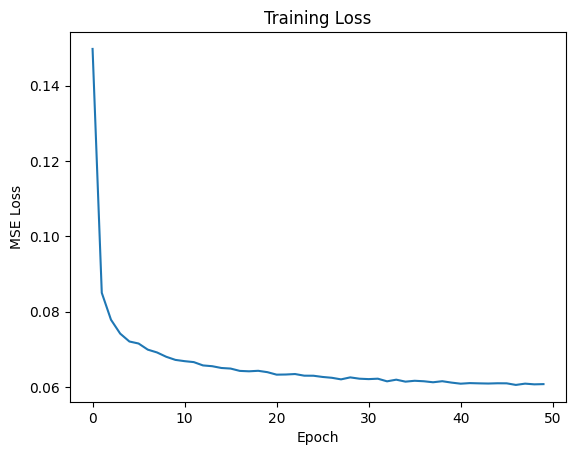

In [32]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.show()

In [33]:
@torch.no_grad()
def ddpm_sample(model, n_samples=16):
    model.eval()

    x = torch.randn(
        n_samples, 1, 28, 28,
        device=device
    )

    for t in reversed(range(T)):
        t_batch = torch.full(
            (n_samples,),
            t,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(x, t_batch)

        beta_t = betas[t]
        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]

        mean = (
            1 / torch.sqrt(alpha_t)
            * (
                x
                - (beta_t / torch.sqrt(1 - alpha_bar_t))
                * predicted_noise
            )
        )

        if t > 0:
            alpha_bar_prev = alpha_bars[t - 1]
            posterior_variance = (
                beta_t
                * (1 - alpha_bar_prev)
                / (1 - alpha_bar_t)
            )

            noise = torch.randn_like(x)
            x = mean + torch.sqrt(posterior_variance) * noise
        else:
            x = mean

    return x.clamp(-1, 1)

In [34]:
samples_ddpm = ddpm_sample(model, n_samples=16)
print(samples_ddpm.shape)

torch.Size([16, 1, 28, 28])


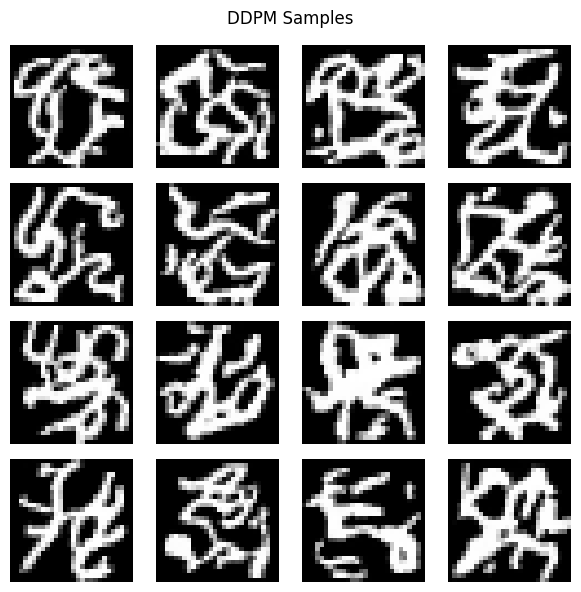

In [35]:
fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(denorm(samples_ddpm[i, 0]).cpu(), cmap="gray")
    ax.axis("off")

plt.suptitle("DDPM Samples")
plt.tight_layout()
plt.show()

In [36]:
@torch.no_grad()
def ddim_sample(model, n_samples=16, n_steps=50):
    model.eval()

    x = torch.randn(
        n_samples, 1, 28, 28,
        device=device
    )

    timesteps = torch.linspace(
        0, T - 1, n_steps,
        device=device
    ).long()

    for i in reversed(range(len(timesteps))):
        t = timesteps[i]

        t_batch = torch.full(
            (n_samples,),
            t.item(),
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(x, t_batch)

        alpha_bar_t = alpha_bars[t]

        x0_pred = (
            x - torch.sqrt(1 - alpha_bar_t) * predicted_noise
        ) / torch.sqrt(alpha_bar_t)

        if i > 0:
            t_previous = timesteps[i - 1]
            alpha_bar_previous = alpha_bars[t_previous]

            x = (
                torch.sqrt(alpha_bar_previous) * x0_pred
                + torch.sqrt(1 - alpha_bar_previous) * predicted_noise
            )
        else:
            x = x0_pred

    return x.clamp(-1, 1)

In [37]:
samples_ddim_50 = ddim_sample(
    model,
    n_samples=16,
    n_steps=50
)

print(samples_ddim_50.shape)

torch.Size([16, 1, 28, 28])


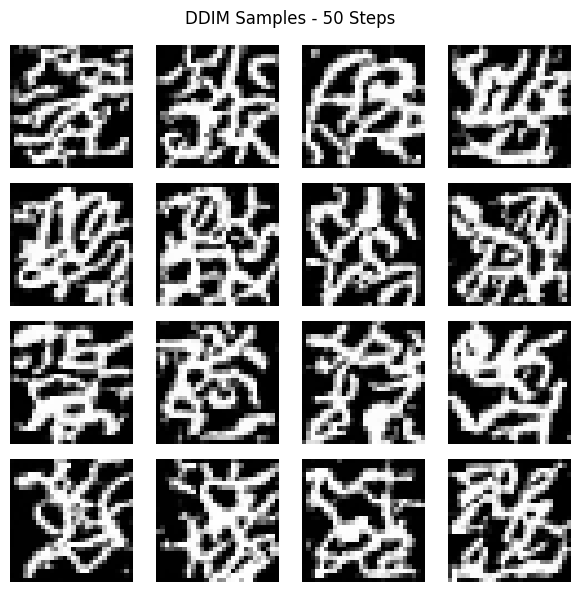

In [38]:
fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(denorm(samples_ddim_50[i, 0]).cpu(), cmap="gray")
    ax.axis("off")

plt.suptitle("DDIM Samples - 50 Steps")
plt.tight_layout()
plt.show()

In [39]:
samples_ddim_20 = ddim_sample(
    model,
    n_samples=16,
    n_steps=20
)

print(samples_ddim_20.shape)

torch.Size([16, 1, 28, 28])


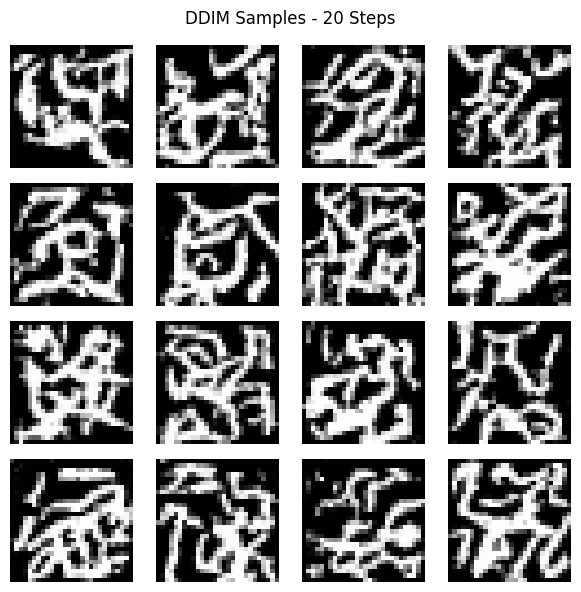

In [40]:
fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(denorm(samples_ddim_20[i, 0]).cpu(), cmap="gray")
    ax.axis("off")

plt.suptitle("DDIM Samples - 20 Steps")
plt.tight_layout()
plt.show()

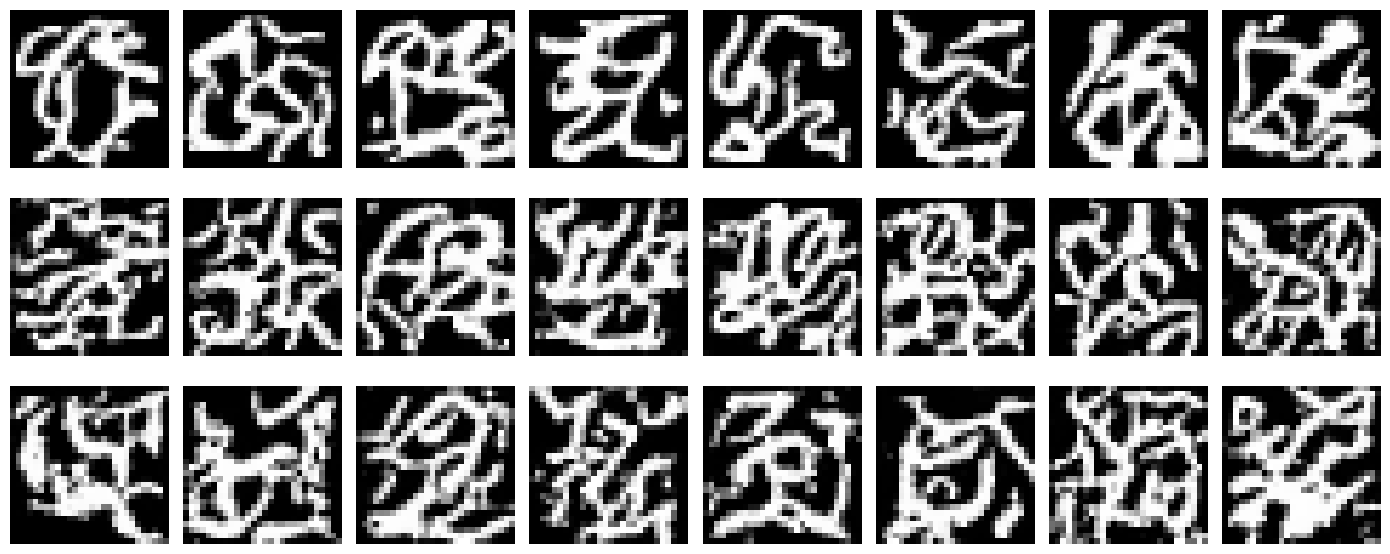

In [41]:
fig, axes = plt.subplots(3, 8, figsize=(14, 6))

sample_groups = [
    (samples_ddpm, "DDPM - 100 steps"),
    (samples_ddim_50, "DDIM - 50 steps"),
    (samples_ddim_20, "DDIM - 20 steps")
]

for row, (samples, title) in enumerate(sample_groups):
    for col in range(8):
        axes[row, col].imshow(
            denorm(samples[col, 0]).cpu(),
            cmap="gray"
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(title, fontsize=11)

plt.tight_layout()
plt.show()

### DDPM vs. DDIM

- DDPM uses 100 steps and adds random noise.
- DDIM uses fewer steps and is faster.
- DDIM with 50 steps usually gives better images than 20 steps.
- The images are noisy because the model is small and trained on 28×28 MNIST images.